# Example of Cosmology

The goal of time-delay cosmography (TDC) analyses is, naturally, deriving new constraints on cosmological parameters. The `Cosmology` module therefore provides a straightforward interface for computing various TDC quantities, from Fermat potential differences between lensed quasar image pairs through measurements of $\rm H_0 \times \lambda_{\rm int}$ for an individual lens, that can subsequently be passed onward to hierarchical frameworks such as [hierarc](https://github.com/TDCOSMO/hierArc) for multi-lens analyses. The class can be initialized with information about the lens and (optionally, for TDC analyses) information for kinematics modeling.

In this example, we analyze the lens model posteriors of a simulated quadruply imaged quasar. All `dolphin` components, such as input data, configuration file, output file, etc., can be found at the following [GitHub repository](https://github.com/brady-ryan/pipeline_dolphin).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from dolphin.analysis.cosmology import Cosmology

H0 = 68
Om0 = 0.3
cosmo_fiducial = FlatLambdaCDM(H0=H0, Om0=Om0)

io_directory="simulation"
lens_name="lensed_agn"
model_id="jax"

z_lens = 0.481053
z_source = 0.788751
sigma_v_observed = 270
sigma_v_observed_error = 10

walker_ratio = 10
burn_in = 0
n_samples = 5000
rng_seed=42

# approximate JWST/NIRSpec parameters
kwargs_seeing = {"psf_type": "GAUSSIAN", "fwhm": 0.14}

kwargs_aperture = {
    "aperture_type": "slit",
    "length": 0.55,
    "width": 0.55,
    "center_ra": 0.00,
    "center_dec": 0,
    "angle": 0,
}

kwargs_numerics_galkin = {
    "interpol_grid_num": 1000,
    "log_integration": True,
    "max_integrate": 1e3,
    "min_integrate": 1e-4,
}

kwargs_kin_api = {"kwargs_numerics_galkin": kwargs_numerics_galkin,
                  "sampling_number": 1000,
                  "Hernquist_approx": False,
                  "MGE_light": True,
                  "MGE_mass": False,
                  "kinematics_backend": "galkin"
                }

cosmology = Cosmology(io_directory=io_directory,
                      lens_name=lens_name,
                      model_id=model_id,
                      z_lens=z_lens,
                      z_source=z_source,
                      cosmo_fiducial=cosmo_fiducial,
                      lens_model_kinematics_bool=[True, False],
                      light_model_kinematics_bool=[True, True],
                      kwargs_seeing=kwargs_seeing,
                      kwargs_aperture=kwargs_aperture,
                      anisotropy_model="const",
                      walker_ratio=walker_ratio,
                      burn_in=burn_in,
                      n_samples=n_samples,
                      **kwargs_kin_api
                    )

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


The procedure for cosmological inference through this module is as follows:

# 1. (Optional) Compute Fermat Potential differences between Image Pairs

`Cosmology.fermat_potential()` samples the lens mass and point source position posteriors to obtain the Fermat potential differences between image pairs, given by the equation:
$$
\Delta \Phi_{\rm AB} = \frac{(\theta_{\rm A} - \beta)^2}{2} - \frac{(\theta_{\rm B} - \beta)^2}{2} - \psi_{\rm A} + \psi_{\rm B},
$$
where $\theta_{\rm i}$ are the image position posteriors, $\psi_{\rm i}$ are the lensing potentials determined from the mass model posteriors, and $\beta$ is the source position computed from the lens and image configuration.

In [3]:
fermat_samples = cosmology.fermat_potential()

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


# 2. Compute the Time-Delay Distance

One can compute the modeled time-delay distance, $\rm D_{\Delta t, model}$, in two ways:

1. **Direct sampling:** sample directly during the modeling phase using the `time_delay_likelihood` model type in `special`.
2. **Post-processing:** combine the Fermat potential samples from Step 1 with the measured time delays via `Cosmology.ddt_from_time_delay()`.

In the second approach, the function draws time delays from a Gaussian distribution with mean and standard deviation set by the measured values and their uncertainties. It then computes

$$
\rm D_{\Delta t, model} = \frac{c \, \Delta t_{AB}}{\Delta \Phi_{AB}},
$$

where $c$ is the speed of light, $\rm \Delta t_{AB}$ is the time delay between images A and B, and $\rm \Delta \Phi_{AB}$ is the Fermat potential difference between them. Because $\rm \Delta \Phi_{AB}$ is a posterior distribution from Step 1, the result is an array of time-delay distance samples for each image pair rather than a single value.

> **Note:** For quadruply imaged systems, we recommend that users sample the time-delay distance directly during modeling with `time_delay_likelihood`. The standalone computation here treats each image pair independently and therefore ignores the covariances between the Fermat potential differences.

In [4]:
dt_measured = [37.94, 58.82, 61.83]
dt_measured_uncertainty = [1., 1., 1.]

ddt_independent = cosmology.ddt_from_time_delay(fermat_model_samples=fermat_samples,
                                          dt_measured=dt_measured,
                                          dt_measured_uncertainty=dt_measured_uncertainty)


# In this example, as recommended, D_dt was sampled directly during the modeling
# process. We will therefore use those posteriors for the cosmological inference.

def load_chain(output, param_names, name, model_id, walker_ratio, burn_in):
    """
    Extract specific parameters from `output`
    """

    chain = output.get_reshaped_emcee_chain(
        name, model_id, walker_ratio, burn_in=burn_in
    )

    num_params = output.num_params_sampled

    if len(param_names) == 0:
        parameter_list = np.arange(num_params)
    else:
        parameter_list = []
        for i in param_names:
            if i in output.params_sampled:
                parameter_list.append(output.params_sampled.index(i))
            else:
                raise ValueError(
                    f"Parameter '{i}' not found. Available parameters: {output.params_sampled}"
                )

    # Flatten walkers x steps for each requested parameter
    raw_samples = {}
    for i in parameter_list:
        param_name = output.params_sampled[i]
        raw_samples[param_name] = chain[:, :, i].flatten()

    return raw_samples

rng = np.random.default_rng(seed=rng_seed)
ddt_all = load_chain(cosmology.output, ["D_dt"], "lensed_agn", "jax", 10, 0)["D_dt"]
random_indices = rng.choice(ddt_all.size, size=n_samples, replace=False)
ddt_model = ddt_all[random_indices]

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


# 3. Sample $\rm H_0$ from the Time-Delay Distances

Given the time-delay distance samples from Step 2, one can infer $\rm H_0$ with `calculate_sampled_h0()`. The function marginalizes over $\Omega_{\rm m}$ in a flat LCDM cosmology, so the result depends on the assumed prior range, which one can set with `Om_min` and `Om_max`.

1. Using the fiducial cosmology from the `Cosmology` class initialization, the function computes the ratio of the angular diameter distances to the source and between the lens and source:

   $$
   \rm R_{fid} = \frac{D_{s,fid}}{D_{ds,fid}}.
   $$

2. One value of $\Omega_{\rm m}$ is drawn per MCMC realization from a uniform prior,

   $$
   \Omega_{\rm m} \sim \mathcal{U}(\rm \Omega_{\rm m, min}, \Omega_{\rm m, max}),
   $$

   with defaults of 0.05 and 0.5.

3. For each sample $i$, a new flat LCDM cosmology is constructed with the fiducial $\rm H_0$ and the drawn $\Omega_{{\rm m},i}$. From it, the function computes the angular diameter distances $\rm D_d$, $\rm D_s$ and $\rm D_{ds}$, and the predicted time-delay distance

   $$
   \rm D_{\Delta t, cosmo} = (1 + z_d)\frac{D_d D_s}{D_{ds}}.
   $$

4. Since $\rm D_{\Delta t} \propto H_0^{-1}$, the $\rm H_0$ value for each realization and image pair follows from rescaling the fiducial $\rm H_0$:

   $$
   \rm H_{0,i} = H_{0,fid} \, \frac{D_{\Delta t, cosmo}(\Omega_{m,i})}{D_{\Delta t, model,i}}.
   $$

   The same cosmology is used for every image pair within a realization, so $\rm H_0$ is calculated independently for each pair but shares the same $\Omega_{\rm m}$ draw.

5. For each realization, the function also returns

   $$
   \rm g_i = \sqrt{\frac{R_i}{R_{fid}}}, \qquad R_i = \frac{D_{s}}{D_{ds}},
   $$

   which captures how the kinematic prediction depends on the cosmology relative to the fiducial one. These weights can be input to the `compute_log_kinematic_likelihood()` function, which is detailed in the Step 6.

In [5]:
# No kappa_ext in simulation
kappa_ext_samples = np.zeros(n_samples)
ddt_corrected = ddt_model / (1 - kappa_ext_samples)

h0_sampled, om_draws, g_samples = cosmology.calculate_sampled_h0(ddt_samples=ddt_corrected,
                                                                 Om_min=0.05,
                                                                 Om_max=0.5)

# 4. Compute the Dimensionless Velocity Dispersion

For weighting, the resultant $\rm H_0$ samples need a model prediction of the velocity dispersion for every MCMC realization. This is computed with `velocity_dispersion_dimension_less()`, which returns the dimensionless quantity $\rm J$ defined by Eq. 4.11 in Birrer et al. 2016; Eq. 6 in Birrer et al. 2019

$$
\rm \sigma_v^2 = \frac{D_d}{D_{ds}} \, c^2 \, J(\theta_{\rm E}, \gamma, r_{\rm eff}, \beta_{ani}).
$$

$\rm J$ depends only on angular quantities (the lens and light profiles and the stellar anisotropy), not on cosmology. This is why it can be computed once from the lens model chain and then combined with any cosmology in Step 5. The $\rm J$ returned here does not include an external mass sheet correction. That correction is applied through $\rm \kappa_{ext}$ in Step 5.

1. The effective radius is needed to compute the velocity dispersion within the model.
   - **Single-component lens light:** $\rm r_{eff}$ is taken directly from the sampled `R_sersic_lens_light0` parameter.
   - **Multi-component lens light:** $\rm r_{eff}$ must be computed for each sample. The function first tries to load a saved morphology chain with `Photometry.load_morphology_chain()`. If none exists, it runs `Photometry.do_linear_inversion()` with the supplied `band_config` to compute it.

2. For each sample, the `kwargs_anisotropy` dictionary is built through the provided `beta_draws`.

3. Together with $\rm r_{eff}$, $\rm \theta_E$ and the power-law slope $\gamma$ of the main deflector, they are passed to lenstronomy's `TDCosmography.velocity_dispersion_dimension_less()`.

In [6]:
# address Mass-Anisotropy Degeneracy
# simulation has no anisotropy, so probe
# small changes as an example
beta_min, beta_max = -0.03, 0.03 
beta_draws = rng.uniform(
            size=n_samples,
            low=beta_min,
            high=beta_max,
        )

# build `band_config` for morphology calculation
band_config = {
    "F115W": {
        "lens_light_indices": [0, 1],
        "source_indices": [0, 1],
        "exclude_lens_light_indices": [],
    }
}

sigma_v_dimensionless = cosmology.velocity_dispersion_dimension_less(beta_draws=beta_draws,
                                                                     band_config=band_config,
                                                                     kinematics_band="F115W")

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


# 5. Compute the Kinematic Likelihood

The kinematic likelihood compares the observed velocity dispersion of the main deflector to the one predicted by the lens model for each realization. It is computed with `compute_logarithmic_kinematic_likelihood()`. The result can be used to weight the $\rm H_0$ samples from Step 3.

1. One value is drawn per MCMC realization from the same uniform prior,

   $$
   \Omega_{\rm m} \sim \mathcal{U}(\rm \Omega_{\rm m, min}, \Omega_{\rm m, max}).
   $$

2. For each sample $i$, a flat LCDM cosmology is constructed with the fiducial $\rm H_0$ and the drawn $\Omega_{{\rm m},i}$. From it, the function computes the angular diameter distances $\rm D_d$ and $\rm D_{ds}$.

3. The dimensionless quantity $\rm J$ is converted to a velocity dispersion in km/s,

   $$
   \rm \sigma_{v,i} = c \sqrt{\frac{D_d}{D_{ds}} J_i},
   $$

   where $c$ is the speed of light in km/s.

4. The predicted velocity dispersion is computed as

   $$
   \rm \sigma_{v,pred,i} = \sqrt{1 - \kappa_{ext,i}} \; g_i \; \sigma_{v,i}.
   $$

5. Assuming a Gaussian measurement uncertainty, the log-likelihood for each realization is

   $$
   \rm \ln \mathcal{L}_i = -\frac{1}{2} \left( \frac{\sigma_{v,obs} - \sigma_{v,pred,i}}{\sigma_{\sigma_{v, obs}}} \right)^2.
   $$

In [7]:
ln_kin_weight = cosmology.compute_logarithmic_kinematic_likelihood(
    sigma_v_observed=sigma_v_observed,
    sigma_v_observed_error=sigma_v_observed_error,
    J_dimensionless_samples=sigma_v_dimensionless,
    kappa_ext_samples=kappa_ext_samples,
    g_samples=g_samples
)

# 6. Compute the BIC Weight

When several lens models are considered for the same system, the models can be combined by weighting each one according to its Bayesian Information Criterion (BIC). The weight is computed with `compute_bic_weight()`. Models with a BIC close to the best one receive a weight near 1, and models with a much higher BIC are downweighted exponentially.

The BIC of the current model, $\rm BIC_{model}$, is treated as a Gaussian random variable with an intrinsic scatter $\rm \sigma_{BIC}$, to account for the fact that small BIC differences are not significant. The weight is the piecewise function

$$
\rm f(x) =
\begin{cases}
1 & x < BIC_{min} \\
\exp\left[-\frac{1}{2}(x - BIC_{min})\right] & x \geq BIC_{min}
\end{cases}
$$

convolved with the Gaussian:

$$
\rm w_{BIC} = \int f(x) \, \mathcal{N}(x \,|\, BIC_{model}, \sigma_{BIC}^2) \, dx.
$$

In [8]:
# list of all model BICs, including the current one
# since we are only analyzing one model, this part is an
# example of how it would be done in practice
bic_all = [16992.15804715, 40000] # very large second BIC that carries no weight

bic_weight = cosmology.compute_bic_weight(bic_all)

# 7. Flat $\rm H_0$ Weight

The lens model samples $\rm D_{\Delta t}$, not $\rm H_0$, and implicitly assumes a prior that is uniform in $\rm D_{\Delta t}$. Because $\rm H_0 \propto D_{\Delta t}^{-1}$, a prior that is uniform in $\rm H_0$ corresponds to a prior proportional to $\rm |dH_0/dD_{\Delta t}| \propto D_{\Delta t}^{-2}$. Each realization is therefore weighted by

$$
\rm w_{flat H_0} = \frac{H_{0,i}}{D_{\Delta t, model,i}}.
$$

Since $\rm H_{0,i} \propto 1/D_{\Delta t, model,i}$ at fixed $\rm \Omega_m$, this is proportional to $\rm D_{\Delta t, model,i}^{-2}$.

In [9]:
w_flat_H0 = h0_sampled[:, 0] / ddt_corrected

# 8. Combine the Weights

The final $\rm H_0$ posterior is obtained by weighting each realization with the terms computed in the previous steps. Working in log space avoids numerical underflow, because the kinematic log-likelihood can be a large negative number. The weights multiply, so their logarithms add:

$$
\rm \ln w_i = \ln \mathcal{L}_{kin,i} + \ln w_{flat H_0,i} + \ln w_{BIC}.
$$

In [10]:
ln_weights = ln_kin_weight + np.log(w_flat_H0) + np.log(bic_weight)

def normalize_ln_weights(ln_w):
    """Stable conversion of log weights to normalized weights."""
    ln_w = np.asarray(ln_w, dtype=float)
    ln_w = ln_w - np.max(ln_w[np.isfinite(ln_w)])
    w = np.exp(ln_w)
    return w / np.sum(w)

# normalize the weights
weights = normalize_ln_weights(ln_weights)

# Display the results!

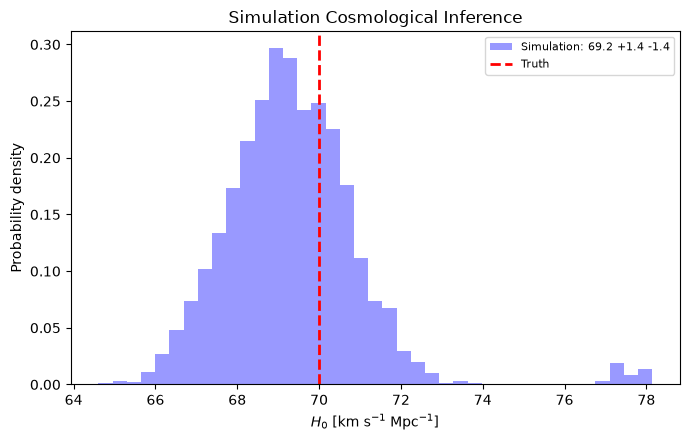

In [11]:
def wquantile(values, weights, percentiles):
    """Obtain specified percentiles from input values
    and weights
    """
    
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    m = np.isfinite(v) & np.isfinite(w) & (w > 0)
    v, w = v[m], w[m]
    if v.size == 0:
        return [np.nan for _ in percentiles]
    order = np.argsort(v)
    v, w = v[order], w[order]
    cdf = np.cumsum(w) / np.sum(w)
    qs = np.asarray(percentiles, dtype=float) / 100.0
    idx = np.clip(np.searchsorted(cdf, qs, side="left"), 0, v.size - 1)
    return v[idx].tolist()

def summary_label(name, values, weights):
    """Create label from quantiles"""
    p16, p50, p84 = wquantile(values, weights, [16, 50, 84])
    return f"{name}: {p50:.1f} +{p84 - p50:.1f} -{p50 - p16:.1f}"

lo = min(np.min(h) for h in h0_sampled[:, 0])
hi = max(np.max(h) for h in h0_sampled[:, 0])
bins = np.linspace(lo, hi, 40)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(
    h0_sampled[:, 0],
    bins=bins,
    weights=weights,
    density=True,
    color="blue",
    alpha=0.4,
    label=summary_label("Simulation", h0_sampled[:, 0], weights),
)

ax.axvline(x=70, color='r', linestyle='--', linewidth=2, label='Truth')

ax.set_xlabel(r"$H_0$ [km s$^{-1}$ Mpc$^{-1}$]")
ax.set_ylabel("Probability density")
ax.set_title("Simulation Cosmological Inference")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()